# 📰 Before the Code: How Text Becomes Numbers, and How BERT Reads (study notes)

> 📝 **Note:** Before starting this project I had **zero background** in working with text (NLP), Transformers or BERT. This cell was **written by Claude (AI)** at my request, so I could understand the big picture before typing the code. All the **code** below this cell is typed by me while following the video.
>
> Every picture and number here is **real**: computed from this dataset and the real `bert-base-uncased` model, with the same settings as this notebook.

**The goal of this notebook:** read one news headline and say whether it's **sarcastic (1)** or **not sarcastic (0)**.

```
📰 headline  →  ✂️ tokens  →  🔢 token IDs  →  🧠 BERT  →  📦 [CLS] summary (768 numbers)  →  ⚖️ small judge  →  0.93 = "93% sure it's sarcastic"
```

---

## 1. The data

`Sarcasm_Headlines_Dataset.json` has **26,709 headlines** and 3 columns: `article_link`, `headline`, and `is_sarcastic`.

| Headline (real examples) | `is_sarcastic` |
|---|---|
| fitbit releases new tracking collar that gets tighter every second you are inactive | **1** 😏 |
| desktop zen rock garden thrown at assistant | **1** 😏 |
| horrified pope calls philadelphia humanity's greatest sin against god | **1** 😏 |
| 30 unbeleafably adorable gifts for plant lovers | 0 |
| dodd-frank at four | 0 |
| how these psychologists are prioritizing mental health care for black america | 0 |

- **14,985** are not sarcastic (56%) and **11,724** are sarcastic (44%), so the two classes are fairly balanced.
- Fun fact: **every** sarcastic headline comes from **The Onion** (a satire website that writes fake, funny news), and **every** normal headline comes from **HuffPost** (a real news website).
- This is **binary classification** (2 classes), the same kind of problem as the rice in Project 01.

---

## 2. The big problem: computers only understand numbers

| Project | The input | How it became numbers |
|---|---|---|
| 01 Rice | a table | it already was numbers |
| 02–03 Photos | images | every pixel is already a number (brightness) |
| 04 Quran | sound | the microphone measured the air 48,000 times per second |
| **05 Headlines** | **text** | ❓ |

A word is **not** a number. We could turn every **letter** into a number (`a` = 1, `b` = 2, ...), but that's useless: the numbers would say nothing about **meaning**. "cat" and "car" would look almost the same, while "cat" and "kitten" would look totally different.

The solution has **3 steps**: cut the text into pieces (§3), look up a number for every piece (§3), then give every number a **meaning** (§5). After that, **BERT** reads the whole sentence (§6–§8).

---

## 3. Step 1: the tokenizer ✂️ cuts the text into pieces

A **tokenizer** is like a **dictionary with page numbers**. It cuts the headline into small pieces called **tokens**, and replaces every token with its **number in the dictionary** (its **token ID**):

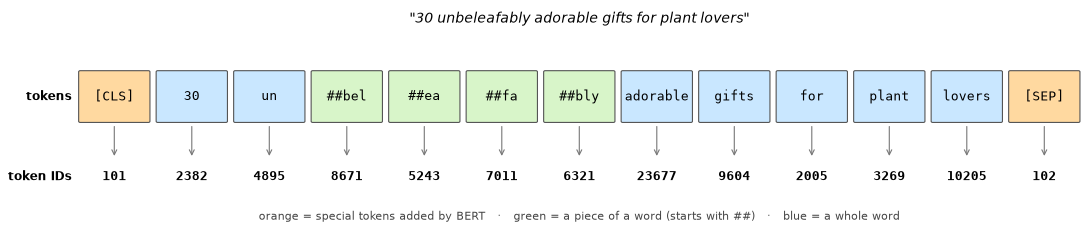

- BERT's dictionary has **30,522 tokens**. This list is called the **vocabulary**.
- `bert-base-uncased` means "**uncased**": everything is made **lowercase** first, so "Pope" and "pope" are the same token.
- **What if a word is not in the dictionary?** It's cut into **smaller pieces** that are. `unbeleafably` is a made-up pun (unbelievably + leaf), but BERT can still read it: `un` + `##bel` + `##ea` + `##fa` + `##bly`. The `##` means "this piece is glued to the piece before it". So BERT **never** meets a word it can't handle.
- The tokenizer also adds **special tokens**:

| Token | ID | Job |
|---|---|---|
| `[CLS]` | 101 | always the **first** token. Its job is to become the **summary** of the whole sentence (see §8) |
| `[SEP]` | 102 | marks the **end** of the sentence |
| `[PAD]` | 0 | an empty "filler" token (see §4) |
| `[UNK]` | 100 | "unknown" (rarely needed, thanks to the `##` pieces) |
| `[MASK]` | 103 | a hidden word, used when BERT was trained (see §7) |

---

## 4. Step 2: make every headline the same length 📏

Remember Project 02 and 04: the DataLoader can only **stack** things that have the **same size**. Headlines have different lengths, so every headline is made exactly **100 tokens** long:

```python
tokenizer(x, max_length = 100, truncation = True, padding = 'max_length', return_tensors = 'pt')
```

| Part | Plain meaning |
|---|---|
| `max_length = 100` | every headline becomes exactly 100 tokens |
| `truncation = True` | if it's longer than 100, cut the end off |
| `padding = 'max_length'` | if it's shorter, fill the rest with `[PAD]` (ID 0) |
| `return_tensors = 'pt'` | give the result as PyTorch tensors |

Our example headline after this line (100 positions):

| Position | Token | `input_ids` | `attention_mask` |
|---|---|---|---|
| 0 | `[CLS]` | 101 | 1 |
| 1 | 30 | 2382 | 1 |
| 2 | un | 4895 | 1 |
| 3 | ##bel | 8671 | 1 |
| 4 | ##ea | 5243 | 1 |
| 5 | ##fa | 7011 | 1 |
| 6 | ##bly | 6321 | 1 |
| 7 | adorable | 23677 | 1 |
| 8 | gifts | 9604 | 1 |
| 9 | for | 2005 | 1 |
| 10 | plant | 3269 | 1 |
| 11 | lovers | 10205 | 1 |
| 12 | `[SEP]` | 102 | 1 |
| 13 | `[PAD]` | 0 | 0 |
| ... | `[PAD]` | 0 | 0 |
| 99 | `[PAD]` | 0 | 0 |

- `input_ids` = the token numbers. **13** are real and **87** are padding.
- `attention_mask` = a **"please ignore"** list: **1** = a real token, **0** = padding. It tells BERT: *"don't read the empty fillers"*.

Is 100 enough? Yes, easily:

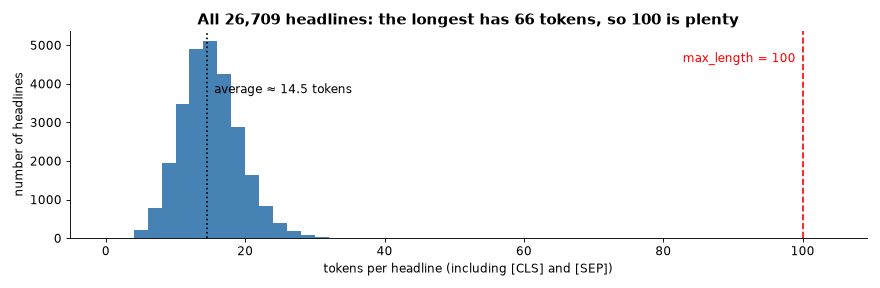

---

## 5. Step 3: give every token a meaning (embeddings) 🗺️

A token ID like `23677` is just a **page number**. Page 23677 ("adorable") is not "a bit more" than page 23676. The number itself has **no meaning**.

So BERT keeps a big table with **one row for each of the 30,522 tokens**, and each row is a list of **768 numbers**. This list is called an **embedding**. For example, the first 5 of the 768 numbers for "king":

```
king  →  [0.010, -0.042, -0.029, -0.002, -0.036, ... 763 more numbers]
```

Think of the 768 numbers as an **address on a "map of meanings"**. Words with similar meanings get similar addresses, so they sit **close together**. A map with 768 directions is impossible to draw, so here it's squeezed down to 2 directions:

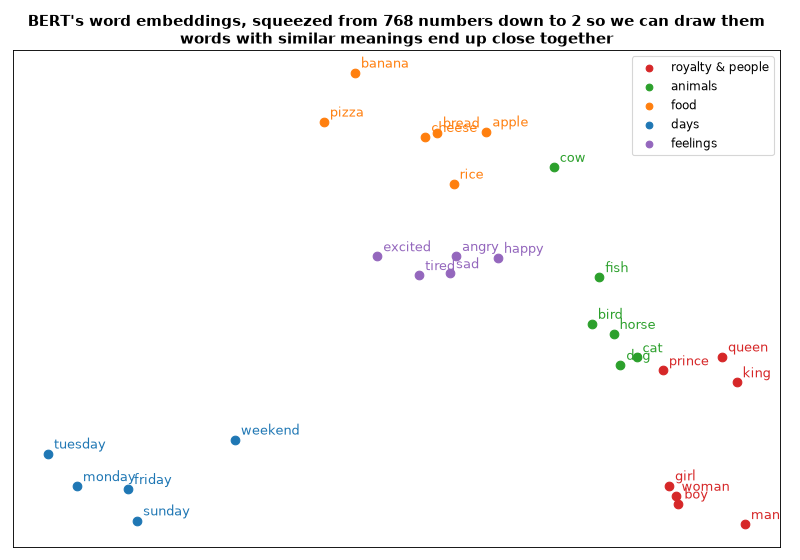

Nobody told BERT that "monday" and "friday" are both days, or that "cat" and "dog" are both animals. It **learned** these addresses by itself while reading a huge amount of text (§7).

---

## 6. Step 4: words change meaning with context, and attention fixes it 👀

**The problem:** the embedding table gives a word **the same 768 numbers every time**. But many words mean different things in different sentences:

- *"the children played on the river **bank**"* 🏞️
- *"he robbed the **bank** and stole the cash"* 🏦

**The solution: attention.** Inside BERT, every word **looks at all the other words** in the sentence and asks: *"which of you help me understand what I mean here?"* It then **mixes in** a bit of their information. After that, "bank" next to "river" and "bank" next to "cash" become **different** lists of numbers.

Real proof. The word "bank" in 4 sentences, before and after BERT (1.00 = exactly the same):

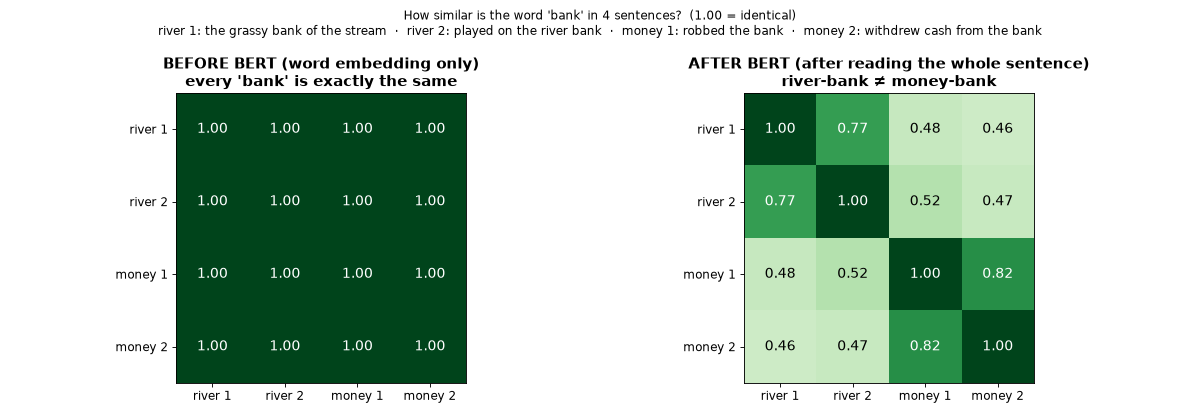

- **Before BERT:** all four "bank"s are identical (1.00).
- **After BERT:** river-bank vs river-bank = **0.77**, money-bank vs money-bank = **0.82**, but river-bank vs money-bank only **0.46–0.52**. BERT understood the difference by itself.

**What does attention look like?** Here are real attention numbers for the headline *"area man thinks he can finish this project by friday"* (each row = one word, darker = it looks more at that column):

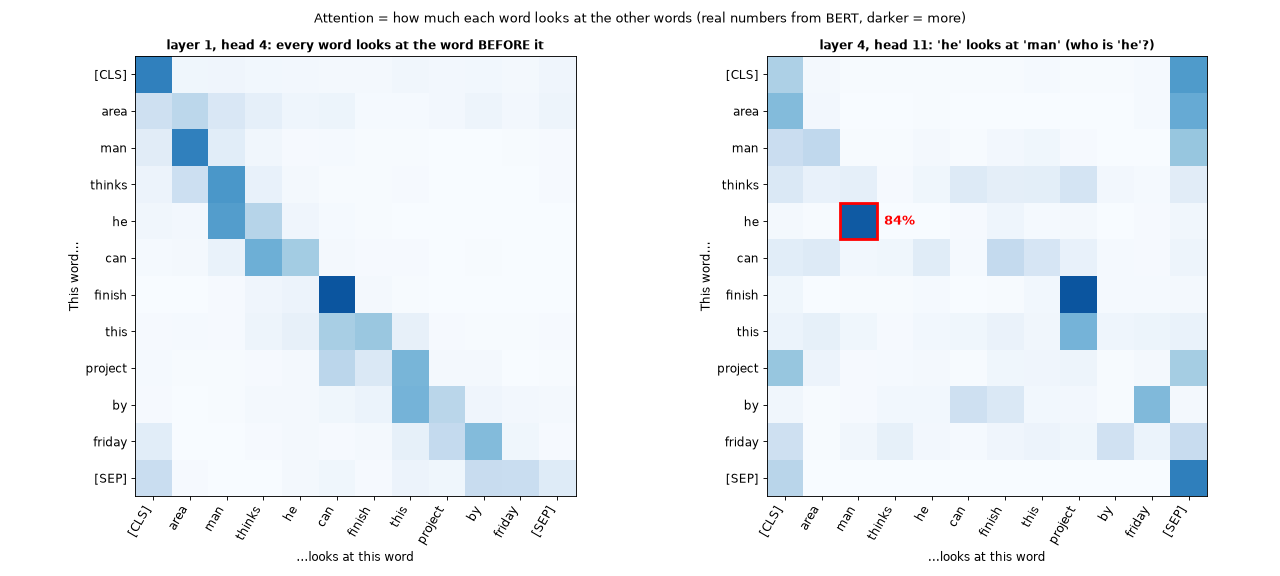

- **Left:** this "reader" learned a simple habit: every word looks at the **word before it**.
- **Right:** this "reader" learned something smarter: **"he"** puts **84%** of its attention on **"man"**. It worked out **who "he" is**. And "finish" looks at "project" (finish *what*? the project).
- Each of these "readers" is called an **attention head**. BERT has **12 heads in every layer**, and each head looks for a different kind of relationship.

---

## 7. So what is BERT? 🧠

**BERT** = **B**idirectional **E**ncoder **R**epresentations from **T**ransformers. In plain words:

| Part of the name | Plain meaning |
|---|---|
| **Transformer** | the kind of model that uses **attention** (§6) |
| **Encoder** | it **reads and understands** text (it doesn't write new text) |
| **Bidirectional** | every word looks **left and right at the same time**, so it sees the whole sentence at once |

Inside `bert-base-uncased`:

```
token IDs (100)  →  embeddings (100 × 768)  →  12 Transformer layers, each with 12 attention heads  →  output (100 × 768)
```

- It has **109,482,240** parameters (numbers it learned). For comparison: our CNN in Project 04 had 139 million, and the rice model in Project 01 had **121**.
- **How did BERT learn all this?** Google trained it on about **3.3 billion words** (English Wikipedia + thousands of books) with a **fill-in-the-blank game**: hide a word with `[MASK]`, and make BERT guess it. After billions of guesses it understands a lot about language.

Real guesses from the same BERT (the parts that play this game are still saved inside the download):

| Sentence | BERT's top 3 guesses for `[MASK]` |
|---|---|
| the capital of france is `[MASK]`. | **paris** 41.7%, lille 7.1%, lyon 6.3% |
| i drink a cup of `[MASK]` every morning. | **coffee** 76.4%, tea 4.8%, it 4.7% |
| monday is the worst `[MASK]` of the week. | **day** 92.5%, night 1.5%, week 1.2% |

> 💡 When you load BERT with `AutoModel.from_pretrained(...)`, a table called **"LOAD REPORT"** lists some keys as **UNEXPECTED** (`cls.predictions...`). Those are exactly the **fill-in-the-blank parts**! We don't need them for sarcasm, so they're simply not loaded. It's **not an error**.

> 📸 Same idea as Project 03: GoogLeNet already "knew how to see" because it was trained on 1.2 million photos. BERT already "knows how to read" because it was trained on billions of words. We just **reuse** that knowledge.

---

## 8. The `[CLS]` token: one summary for the whole headline 📦

BERT gives back **768 numbers for every one of the 100 positions**:

| Step | Shape | Plain meaning |
|---|---|---|
| `input_ids` | `(1, 100)` | 1 headline, 100 token IDs |
| BERT output | `(1, 100, 768)` | 768 numbers for **each** of the 100 tokens (each already "aware" of the whole sentence) |
| `[:, 0]` | `(1, 768)` | keep only **position 0**, which is the `[CLS]` token |

That's what this line in the video's model does:

```python
pooled_output = self.bert(input_ids, attention_mask, return_dict = False)[0][:,0]
```

- `[0]` = the first thing BERT returns: the `(batch, 100, 768)` output.
- `[:,0]` = for **every** headline in the batch (`:`), take **position 0** (`0`), the `[CLS]` token.

**Why `[CLS]`?** It's a **special seat at the front** that doesn't belong to any real word. Through attention, it collects information from **all** the words, so by the end it works as a **summary of the whole headline**: 768 numbers.

**Does that summary already "feel" sarcasm, before any training?** Here are the `[CLS]` summaries of 1,500 real headlines, squeezed to 2 directions:

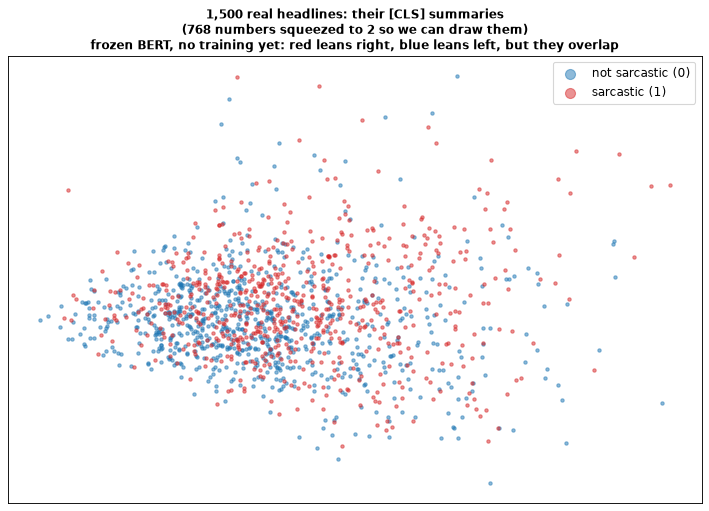

The two colours overlap, but they clearly **lean to different sides**. I also gave the summaries of 2,000 headlines to the simplest possible judge (a logistic regression from scikit-learn) and tested it on 1,000 other headlines: it already got **84.2%** right, with **BERT not trained at all**. That's why we only need to train a **small judge** on top.

---

## 9. Our model: frozen BERT + a small judge ⚖️

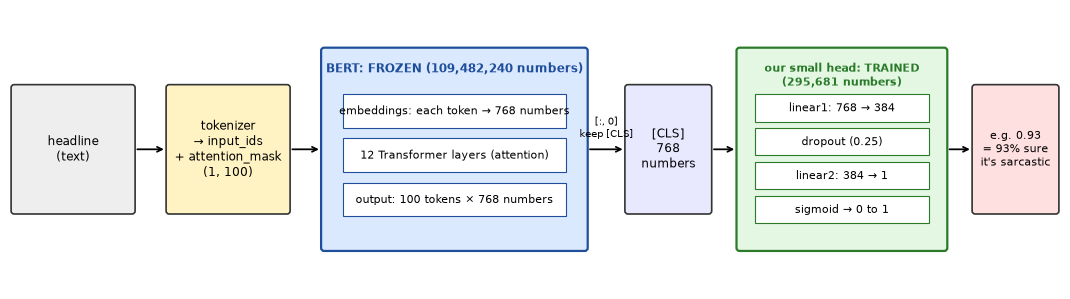

```python
for param in bert_model.parameters():
    param.requires_grad = False
```

- `requires_grad = False` = **freeze** BERT: "don't change these numbers while training". (Project 03 trained everything, here BERT is locked.)
- Only the small head on top learns:

| Layer | Plain meaning | Parameters |
|---|---|---|
| `linear1`: 768 → 384 | 384 "judges" each read the 768-number summary | 295,296 |
| `dropout(0.25)` | randomly switch off **25%** of them while training (like Project 04, but a quarter instead of half) | 0 |
| `linear2`: 384 → 1 | one final judge gives one score | 385 |
| `sigmoid` | squeeze the score into **0 to 1** (exactly like Project 01) | 0 |

- **Total: 109,777,921 parameters, but only 295,681 are trained**. That's just **0.27%** of the model.
- Before training, the head is random, so it says "**about 50%**" for everything: 0.505, 0.525 and 0.504 for three of the headlines above. Training will push sarcastic ones towards **1** and normal ones towards **0**.

> 🧑‍🏫 **Analogy:** BERT is an **expert reader** who has read the whole internet. We don't re-teach them English. We only hire a **small judge** who listens to the reader's one-paragraph summary (`[CLS]`) and decides: "sarcastic or not?".

---

## 10. The answer, the loss, and the training (same as Project 01!)

- The model outputs **1 number from 0 to 1**. Above **0.5** → sarcastic (1), below → not sarcastic (0). That's `prediction.round()`.
- **Loss:** `nn.BCELoss()` (Binary Cross Entropy), the same "penalty score" as the rice model: small when the guess is right and confident, big when it's wrong and confident.
- **Optimizer:** `Adam`, but it can only move the **295,681 unfrozen** numbers.
- Every batch: **guess → measure → find direction → fix**, exactly like every project before.

---

## 11. Where each step lives in this notebook's code

| Step | Code |
|---|---|
| read the JSON file | `pd.read_json(..., lines=True)` (one headline per line) |
| split 70 / 15 / 15 | `train_test_split(...)` twice, like Project 01 |
| download the tokenizer and BERT | `AutoTokenizer.from_pretrained("bert-base-uncased")`, `AutoModel.from_pretrained("bert-base-uncased")` |
| text → `input_ids` + `attention_mask` | `tokenizer(x, max_length=100, truncation=True, padding='max_length', return_tensors='pt')` inside the Dataset |
| BERT → `[CLS]` → judge → 0..1 | `MyModel.forward` |
| freeze BERT | `param.requires_grad = False` |
| loss and optimizer | `nn.BCELoss()`, `Adam(model.parameters(), lr=LR)` |

---

## 12. All 5 projects in one table

| | Input | Becomes numbers by... | Model | Classes |
|---|---|---|---|---|
| 01 | rice measurements | already numbers | 2 Linear layers | 2 |
| 02 | animal photos | pixels | CNN built from scratch | 3 |
| 03 | leaf photos | pixels | pretrained **GoogLeNet**, everything trained | 3 |
| 04 | Quran recitation | sound wave → mel spectrogram | CNN built from scratch | 12 |
| **05** | **news headlines** | **tokenizer → token IDs → embeddings** | **pretrained BERT (frozen) + small head** | **2** |

---

## 13. Mini dictionary

| Word | Simple meaning |
|---|---|
| **NLP** | Natural Language Processing: making computers work with human language |
| **Token** | A piece of text: a word, part of a word (`##bel`), or a special token (`[CLS]`) |
| **Tokenizer** | Cuts text into tokens and turns them into numbers |
| **Vocabulary** | The tokenizer's dictionary: 30,522 tokens for BERT |
| **Token ID** | A token's number in the vocabulary (like a page number) |
| **Padding / `[PAD]`** | Empty fillers that make every headline 100 tokens long |
| **Attention mask** | 1 = real token, 0 = padding ("please ignore") |
| **Embedding** | A list of 768 numbers that works like an address on a "map of meanings" |
| **Context** | The other words around a word, which change what it means |
| **Attention** | Every word looks at the other words and mixes in the useful information |
| **Attention head** | One "reader" that looks for one kind of relationship. BERT has 12 per layer |
| **Transformer** | A model built from attention layers |
| **BERT** | A pretrained Transformer that reads text in both directions |
| **`[CLS]`** | The first token, whose final 768 numbers summarise the whole sentence |
| **Pretrained** | Already trained by someone else on a huge dataset |
| **Freeze** | `requires_grad = False`: these numbers don't change during training |
| **Head** | The small new layers on top of a pretrained model |
| **Sigmoid** | Squeezes a number into 0 to 1 (a probability) |

---

## ✨ Worth knowing (feel free to skip)

- **A possible shortcut:** because every sarcastic headline comes from The Onion and every normal one from HuffPost, the model may partly learn **"this sounds like The Onion's writing style"** instead of real sarcasm. That's fine for learning PyTorch, but it's good to know.
- **Two versions of the data:** the folder also has `Sarcasm_Headlines_Dataset_v2.json` (28,619 headlines). The video uses the first file.
- **Training time on my laptop:** BERT has to read every headline in every epoch, so one epoch takes about **70 seconds**, and 25 epochs take about **30 minutes**.
- The warning **"You are sending unauthenticated requests to the HF Hub"** is harmless. It only means we downloaded BERT without a Hugging Face account.

## References
- Omar M. Atef, [Learn PyTorch in 5 Projects – Tutorial](https://www.youtube.com/watch?v=E0bwEAWmVEM) (freeCodeCamp.org) and the original notebook [Ex_5_Text_Classification_Transformers.ipynb](https://github.com/omaratef3221/pytorch_tutorials/blob/main/Ex_5_Text_Classification_Transformers.ipynb)
- Dataset: [News Headlines Dataset For Sarcasm Detection](https://www.kaggle.com/datasets/rmisra/news-headlines-dataset-for-sarcasm-detection) by Rishabh Misra on Kaggle
- Devlin et al., 2018. [BERT: Pre-training of Deep Bidirectional Transformers for Language Understanding](https://arxiv.org/abs/1810.04805), the original BERT paper
- Vaswani et al., 2017. [Attention Is All You Need](https://arxiv.org/abs/1706.03762), the paper that introduced the Transformer
- Jay Alammar, [The Illustrated BERT, ELMo, and co.](https://jalammar.github.io/illustrated-bert/) and [The Illustrated Transformer](https://jalammar.github.io/illustrated-transformer/), very friendly visual explanations
- Hugging Face docs: [`bert-base-uncased` model card](https://huggingface.co/google-bert/bert-base-uncased) and [Tokenizers summary](https://huggingface.co/docs/transformers/tokenizer_summary)